# Training Model Deteksi Sampah di Google Colab
Notebook ini di-generate berdasarkan code `train.py` agar dapat dijalankan di Google Colab tanpa Google Drive.

In [1]:
import os
import json
import tensorflow as tf
import matplotlib.pyplot as plt
import shutil
from google.colab import files

## Upload Dataset
Silakan upload file `dataset.zip` secara manual. Anda bisa menjalankan cell di bawah ini, atau mendrag & drop file `dataset.zip` secara manual ke panel Files di sebelah kiri.

In [2]:
# Jalankan cell ini untuk mengunggah file dataset.zip melalui prompt
# Atau lewati cell ini jika Anda sudah mengunggahnya secara manual ke sidebar Files.
if not os.path.exists('dataset.zip'):
    uploaded = files.upload()

print("Mengekstrak dataset...")
!unzip -q dataset.zip -d /content/

print("Isi direktori dataset/train:")
!ls /content/dataset/train

Saving dataset.zip to dataset.zip
Mengekstrak dataset...
Isi direktori dataset/train:
Non-Organik  Organik


## Parameter & Data Generator

In [3]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS_INITIAL = 25
EPOCHS_FINE = 30

TRAIN_DIR = "/content/dataset/train"
VAL_DIR = "/content/dataset/val"

os.makedirs("grafik", exist_ok=True)

train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.3,
    horizontal_flip=True,
    fill_mode='nearest',
    brightness_range=[0.8,1.2]
)

val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_data = val_gen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

with open("class_indices.json", "w") as f:
    json.dump(train_data.class_indices, f)

print("Class mapping:", train_data.class_indices)

Found 3373 images belonging to 2 classes.
Found 475 images belonging to 2 classes.
Class mapping: {'Non-Organik': 0, 'Organik': 1}


## Build Model

In [4]:
base_model = ResNet50(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(2, activation='softmax')
])

model.compile(
    optimizer=Adam(1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,430,338 (9.27 MB)

 Trainable params: 172,354 (673.26 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Training Awal (Head Only)

Epoch 1/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.7536 - loss: 0.5021

211/211 ━━━━━━━━━━━━━━━━━━━━ 103s 391ms/step - accuracy: 0.8687 - loss: 0.3117 - val_accuracy: 0.9874 - val_loss: 0.0485
Epoch 2/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.9795 - loss: 0.0786

211/211 ━━━━━━━━━━━━━━━━━━━━ 54s 257ms/step - accuracy: 0.9804 - loss: 0.0699 - val_accuracy: 0.9958 - val_loss: 0.0239
Epoch 3/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.9813 - loss: 0.0551

211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 245ms/step - accuracy: 0.9819 - loss: 0.0552 - val_accuracy: 0.9958 - val_loss: 0.0173
Epoch 4/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.9897 - loss: 0.0326

211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 241ms/step - accuracy: 0.9887 - loss: 0.0370 - val_accuracy: 0.9958 - val_loss: 0.0123
Epoch 5/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 50s 239ms/step - accuracy: 0.9926 - loss: 0.0293 - val_accuracy: 0.9958 - val_loss: 0.0132
Epoch 6/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.9914 - loss: 0.0277

211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 243ms/step - accuracy: 0.9917 - loss: 0.0273 - val_accuracy: 0.9958 - val_loss: 0.0114
Epoch 7/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 83s 245ms/step - accuracy: 0.9929 - loss: 0.0246 - val_accuracy: 0.9958 - val_loss: 0.0117
Epoch 8/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.9984 - loss: 0.0119

211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 244ms/step - accuracy: 0.9967 - loss: 0.0145 - val_accuracy: 0.9958 - val_loss: 0.0100
Epoch 9/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 244ms/step - accuracy: 0.9950 - loss: 0.0156 - val_accuracy: 0.9958 - val_loss: 0.0104
Epoch 10/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 242ms/step - accuracy: 0.9973 - loss: 0.0102 - val_accuracy: 0.9958 - val_loss: 0.0101
Epoch 11/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.9964 - loss: 0.0104

211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 245ms/step - accuracy: 0.9956 - loss: 0.0137 - val_accuracy: 0.9958 - val_loss: 0.0092
Epoch 12/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.9970 - loss: 0.0103

211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 242ms/step - accuracy: 0.9953 - loss: 0.0141 - val_accuracy: 0.9958 - val_loss: 0.0063
Epoch 13/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 240ms/step - accuracy: 0.9973 - loss: 0.0087 - val_accuracy: 0.9937 - val_loss: 0.0139
Epoch 14/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 50s 237ms/step - accuracy: 0.9964 - loss: 0.0102 - val_accuracy: 0.9937 - val_loss: 0.0079
Epoch 15/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 243ms/step - accuracy: 0.9967 - loss: 0.0101 - val_accuracy: 0.9937 - val_loss: 0.0093
Epoch 16/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 244ms/step - accuracy: 0.9961 - loss: 0.0096 - val_accuracy: 0.9958 - val_loss: 0.0076
Epoch 17/25
211/211 ━━━━━━━━━━━━━━━━━━━━ 51s 243ms/step - accuracy: 0.9970 - loss: 0.0093 - val_accuracy: 0.9937 - val_loss: 0.0083


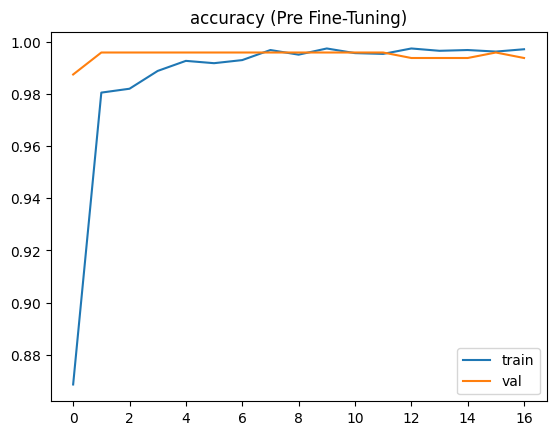

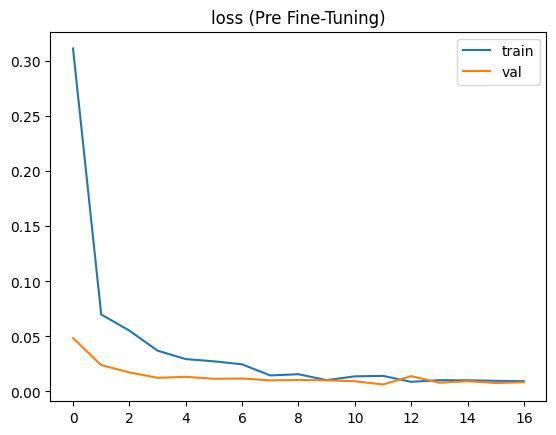

In [5]:
early_stop = EarlyStopping(patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.h5', save_best_only=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS_INITIAL,
    callbacks=[early_stop, checkpoint]
)

for metric in ['accuracy','loss']:
    plt.figure()
    plt.plot(history.history[metric], label='train')
    plt.plot(history.history['val_'+metric], label='val')
    plt.legend()
    plt.title(metric + " (Pre Fine-Tuning)")
    plt.savefig(f"grafik/pre_{metric}.jpg")
    plt.show()
    plt.close()

## Fine Tuning

Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.9672 - loss: 0.1129

211/211 ━━━━━━━━━━━━━━━━━━━━ 97s 346ms/step - accuracy: 0.9715 - loss: 0.0913 - val_accuracy: 0.9979 - val_loss: 0.0059
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.9860 - loss: 0.0442

211/211 ━━━━━━━━━━━━━━━━━━━━ 53s 249ms/step - accuracy: 0.9816 - loss: 0.0611 - val_accuracy: 0.9979 - val_loss: 0.0054
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 53s 250ms/step - accuracy: 0.9804 - loss: 0.0575 - val_accuracy: 0.9958 - val_loss: 0.0076
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 53s 250ms/step - accuracy: 0.9852 - loss: 0.0417 - val_accuracy: 0.9958 - val_loss: 0.0077
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 247ms/step - accuracy: 0.9858 - loss: 0.0467 - val_accuracy: 0.9958 - val_loss: 0.0072
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 245ms/step - accuracy: 0.9905 - loss: 0.0282 - val_accuracy: 0.9979 - val_loss: 0.0072
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.9849 - loss: 0.0470

211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 247ms/step - accuracy: 0.9861 - loss: 0.0395 - val_accuracy: 0.9979 - val_loss: 0.0047
Epoch 8/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 53s 249ms/step - accuracy: 0.9858 - loss: 0.0402 - val_accuracy: 0.9979 - val_loss: 0.0074
Epoch 9/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 53s 251ms/step - accuracy: 0.9896 - loss: 0.0313 - val_accuracy: 0.9979 - val_loss: 0.0068
Epoch 10/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 54s 256ms/step - accuracy: 0.9932 - loss: 0.0184 - val_accuracy: 0.9979 - val_loss: 0.0051
Epoch 11/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 56s 265ms/step - accuracy: 0.9905 - loss: 0.0299 - val_accuracy: 0.9979 - val_loss: 0.0052
Epoch 12/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 52s 246ms/step - accuracy: 0.9917 - loss: 0.0228 - val_accuracy: 0.9979 - val_loss: 0.0052


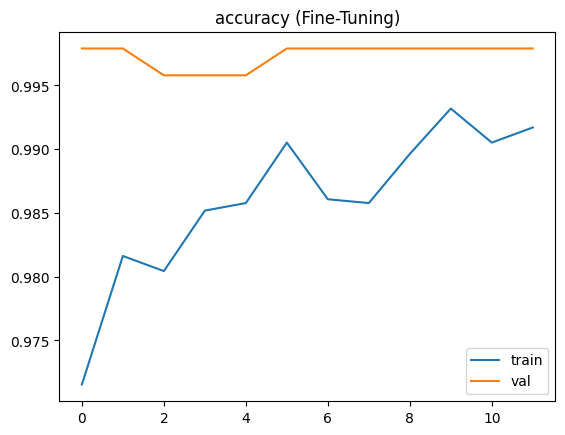

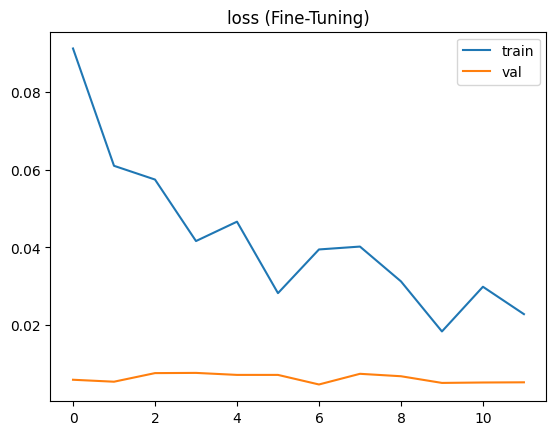

Training selesai ✔️


In [6]:
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS_FINE,
    callbacks=[early_stop, checkpoint]
)

for metric in ['accuracy','loss']:
    plt.figure()
    plt.plot(history_fine.history[metric], label='train')
    plt.plot(history_fine.history['val_'+metric], label='val')
    plt.legend()
    plt.title(metric + " (Fine-Tuning)")
    plt.savefig(f"grafik/fine_{metric}.jpg")
    plt.show()
    plt.close()

print("Training selesai ✔️")

## Testing & Confusion Matrix
Evaluasi performa model menggunakan data test/validasi dan menampilkan Confusion Matrix.

Found 476 images belonging to 2 classes.

Melakukan Prediksi...
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 479ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Organik       1.00      1.00      1.00       240
     Organik       1.00      1.00      1.00       236

    accuracy                           1.00       476
   macro avg       1.00      1.00      1.00       476
weighted avg       1.00      1.00      1.00       476


Accuracy: 100.00%


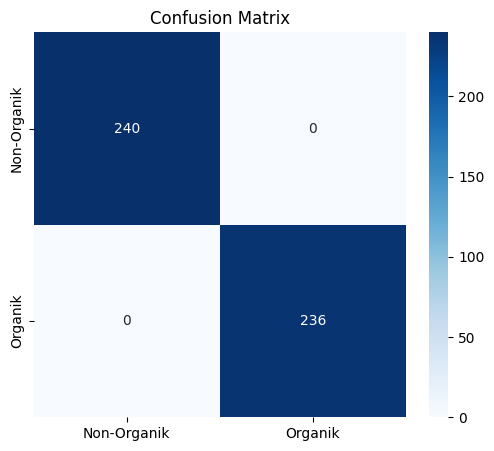

In [ ]:
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Gunakan test_data sebagai data test
TEST_DIR = "/content/dataset/test"

test_gen = ImageDataGenerator(rescale=1./255)
test_data = test_gen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nMelakukan Prediksi...")
pred = model.predict(test_data)
y_pred = np.argmax(pred, axis=1)
y_true = test_data.classes
class_names = list(test_data.class_indices.keys())

print("\nCLASSIFICATION REPORT")
print(classification_report(y_true, y_pred, target_names=class_names))

accuracy = np.mean(y_pred == y_true)
print(f"\nAccuracy: {accuracy*100:.2f}%")

# CONFUSION MATRIX
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names, cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig("grafik/confusion_matrix.jpg")
plt.show()

## Download Hasil Training
Cell ini akan secara otomatis mengunduh hasil model (`.h5`), file konfigurasi kelas (`.json`), serta grafik performa ke komputer Anda.

In [8]:
import shutil
from google.colab import files

# Zip folder grafik agar mudah di-download sekaligus
shutil.make_archive('grafik_hasil', 'zip', 'grafik')

print("Mengunduh file-file hasil...")
try:
    files.download('best_model.h5')
    files.download('class_indices.json')
    files.download('grafik_hasil.zip')
    print("Silakan periksa folder Download di komputer Anda.")
except Exception as e:
    print("Terjadi kesalahan saat download otomatis:", e)
    print("Silakan download secara manual melalui panel Files di kiri.")

Mengunduh file-file hasil...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Silakan periksa folder Download di komputer Anda.
